In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from copy import deepcopy

# Hopfield networks

A Hopfield network is a recurrent neural network that works as a content-addressable memory: it stores a set of patterns $\{ x_i^{(\mu)} \}$, with $\mu = 1,\dots,p$ and $i = 1,\dots,N$ ($N$ neurons/pixels, $p$ patterns), and recalls them starting from incomplete or noisy inputs. The neurons are all connected with symmetric weights given by the Hebb rule

$$
J_{ij} = \frac{1}{N}\sum_{\mu=1}^p x_i^{(\mu)} x_j^{(\mu)}, \qquad J_{ii}=0
$$

and the state $s_i = \pm 1$ evolves with the update rule $s_i \leftarrow \textrm{sgn}\big(\sum_j J_{ij} s_j\big)$, which never increases the energy

$$
E(\vec{s}) = -\frac{1}{2}\sum_{ij} J_{ij} s_i s_j
$$

so the stored patterns are minima of the energy and fixed points of the dynamics. The network is implemented as a Python class, and then extended to the modern Hopfield network.

## Random patterns

Five random $6\times6$ patterns to store:

In [ ]:
#Create 5 random patterns
N_patterns = 5
pattern_size = 6
# store the pattern in a dictionary
random_patterns = {f"pattern {i}": np.random.choice([-1,1], (pattern_size, pattern_size))for i in range(N_patterns)}


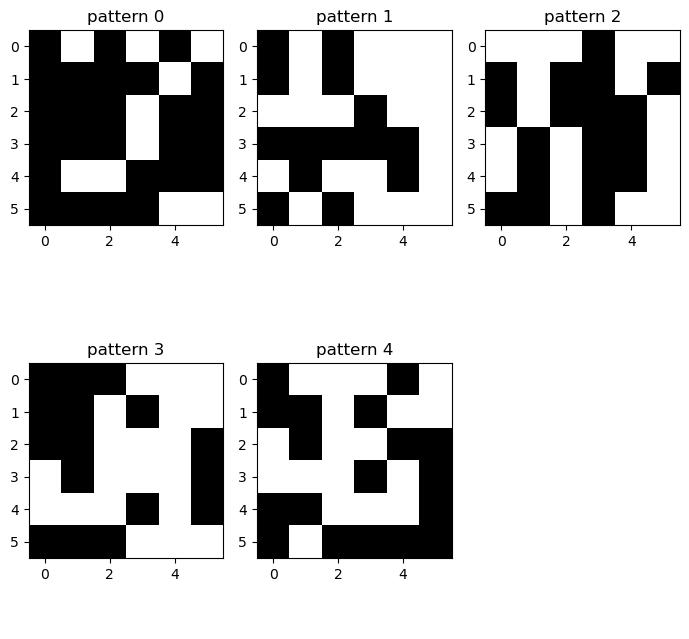

In [ ]:
# visualise the patterns
fig, ax=plt.subplots(2,3, figsize=(7,7))
ax=ax.flatten()
for i, (name,pattern) in enumerate(random_patterns.items()):
    axes=ax[i]
    im=axes.imshow(pattern, cmap="gray", interpolation="none")
    axes.set_title(f"{name}")
ax[5].axis("off")
plt.tight_layout()
plt.show()

## The HopfieldNetwork class

The class stores the patterns (flattened into a matrix of shape $(p, N)$) and the weights, and implements:
- `set_state` / `update_state`: set the state (or a random one) and update it, asynchronously (one random neuron) or synchronously (all neurons)
- `get_similarities`: cosine of the angle between the state and each stored pattern
- `get_energy`: energy of the current state
- `save_history`: state, energy and similarities at every step, used by the plotting methods

In [ ]:
from utils import *  # plotting functions: visualise_hopfield_network, plot_energy, plot_patterns, animate_hopfield_network

In [ ]:
class HopfieldNetwork:
    """Base class for our Hopfield Network (Modern) Hopfield Network"""

    def __init__(self, patterns_dict):
        """Initialises the Hopfield network with a set of patterns."""

       
        
        self.patterns_dict = patterns_dict# the entire dictionary
        
        self.pattern_names = {i: key for i, key in enumerate(patterns_dict.keys())}# the keys of the dictionary
        
        self.patterns = np.concatenate([patterns.flatten() for patterns in patterns_dict.values()]) # the patterns -> the values of the dictionary
        
        self.pattern_shape = next(iter(patterns_dict.values())).shape # the shape of each pattern
       
        # Some useful variables
        self.N_neurons = self.pattern_shape[0]*self.pattern_shape[1]
        self.N_patterns = len(self.pattern_names)
       
        # Flatten the patterns into a matrix of shape (N_patterns, N_neurons)
        self.flat_patterns = np.vstack([pattern.flatten() for pattern in patterns_dict.values()])
        

        self.history={ "state":[],
                       "energy":[],
                       "similarities":[],
                      }
        
        # Initialise the weights and state of the network
        self.w = np.dot(self.flat_patterns.T, self.flat_patterns) / self.N_neurons
        np.fill_diagonal(self.w, 0) #no self-interactions
        self.set_state(random=True)  # initialises the state of the network 

        return 
    
    # =================== INITIALISE AND UPDATE NETWORK STATE  ======================
    
    def set_state(self, state=None, random=False):
        """Sets the state of the Hopfield network. If random = True, sets state to a random vector"""
        if random:
            self.state =np.random.choice([-1, 1], size=self.N_neurons)
        else:
            self.state = state
        self.save_history()

    
    def update_state(self, asynchronous=True):
        # asyncronous updates one neuron at a time
        if asynchronous == True:
                    
            i = np.random.randint(0,self.N_neurons) # choose a random neuron

            self.state[i] = 1 if np.dot(self.w[i, :], self.state) >= 0 else -1
        # synchronous updates all neurons at once
        elif asynchronous == False:
            
            self.state = np.where(np.dot(self.w, self.state) >= 0, 1, -1)
        self.save_history()




    def get_similarities(self, state=None):
        """Compares the state (defaults to the current state of the network to all stored patterns and returns a measure of similarity between the current state and each stored pattern.
        This measure is taken as cos(theta) where theta is the angle between the current state vector and the stored pattern vector in N-D space. 
        """
        state=self.state if state is None else state
        cos_theta=np.zeros(self.N_patterns)
        for i in range(self.N_patterns):
            
            norm_state = np.sqrt(np.dot(state, state))
            norm_pattern = np.sqrt(np.dot(self.flat_patterns[i, :], self.flat_patterns[i, :]))
            if norm_state == 0 or norm_pattern == 0:
                cos_theta[i] = 0
            else:
                cos_theta[i] = np.dot(state, self.flat_patterns[i, :]) / (norm_state * norm_pattern)


        return cos_theta
    
    def get_energy(self, state=None):
        """Returns the energy of the network at a given state"""
        #E=-1/2 S^TJS
        state = self.state if state is None else state
        energy=-0.5*np.dot(np.dot(state.T, self.w), state)
        return energy

    # =================== ANALYSIS AND HISTORY FUNCTIONS ======================
    def save_history(self):
        """Calculates energy and similarites then saves everything to the history of the Hopfield network"""
        self.similarities = self.get_similarities()
        self.energy = self.get_energy()
        self.history["state"].append(self.state.copy())
        self.history["similarities"].append(self.similarities)
        self.history["energy"].append(self.energy)




    

    # =================== PLOTTING FUNCTIONS ==============================

    
    def visualise(self, steps_back=0, fig=None, ax=None, title=None):
        """Visualises the state of the Hopfield network n_steps back (defaults to steps_back=0, i.e. current state)"""
        fig, ax = visualise_hopfield_network( self, steps_back=0, fig=None, ax=None, title=title)
        return fig, ax

    def plot_energy(self, n_steps=None):
        """Plots the energy of the Hopfield network over time. n_steps=None defaults to _all_ steps"""
        fig, ax = plot_energy(self, n_steps=None)
        return fig, ax

    def animate(self, n_steps=10, fps=10, animation_length_secs=5):
        """Animates the last n_steps of the Hopfield network. fps gives frames per second of resulting animation"""
        anim = animate_hopfield_network(self, n_steps=10, fps=10, animation_length_secs=5)

        return anim

## Stored patterns are fixed points

Starting from one of the stored patterns the network stays there, and the energy is constant.

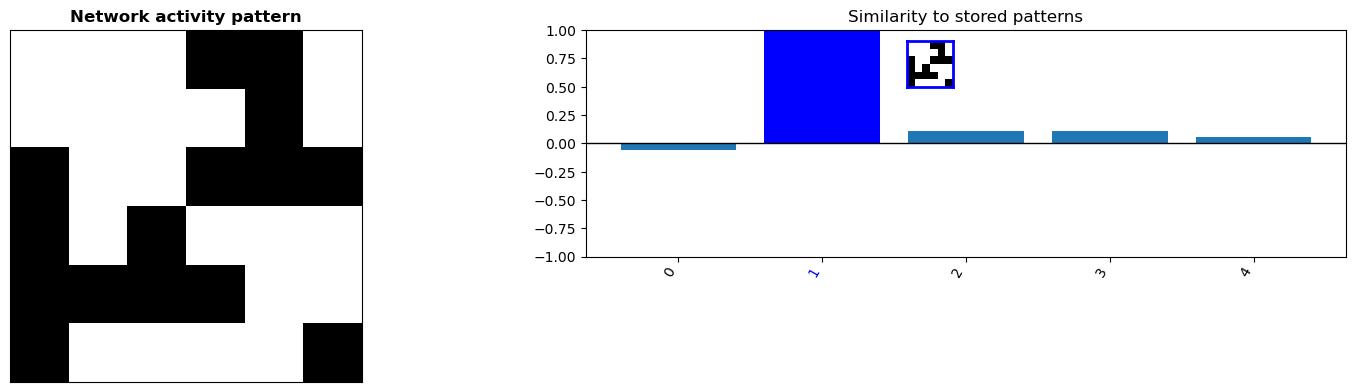

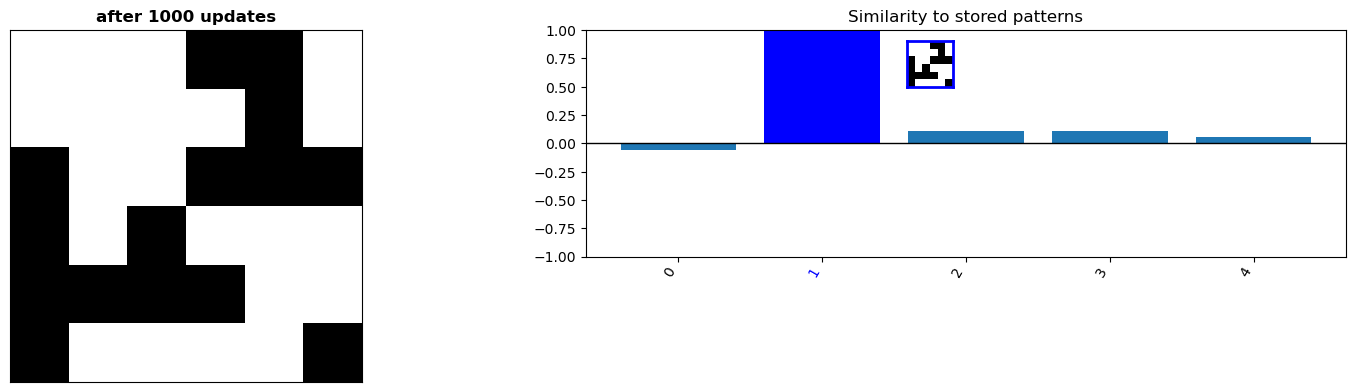

In [ ]:
n_patterns=5
pattern_size = 6
n_updates=1000


patterns= {i: np.random.choice([-1,1], (pattern_size, pattern_size)) for i in range (n_patterns)}
HFN=HopfieldNetwork(patterns) 
#start from one of the stored patterns
initial_pattern = list(patterns.values())[np.random.randint(0,len(patterns))].flatten()  
HFN.set_state(initial_pattern)
HFN.visualise()
for i in range(n_updates):
    HFN.update_state()

HFN.visualise(title=f"after {n_updates} updates")
plt.show()

n_steps: None
n_steps: 1000


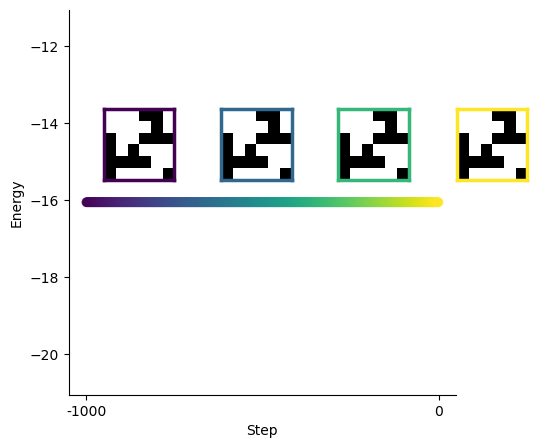

In [ ]:
fig, ax = HFN.plot_energy(n_steps=200)

Starting from a random state, the network evolves towards one of the stored patterns.

(<Figure size 1600x400 with 2 Axes>,
 array([<Axes: title={'center': 'after 1000 updates'}>,
        <Axes: title={'center': 'Similarity to stored patterns'}>],
       dtype=object))

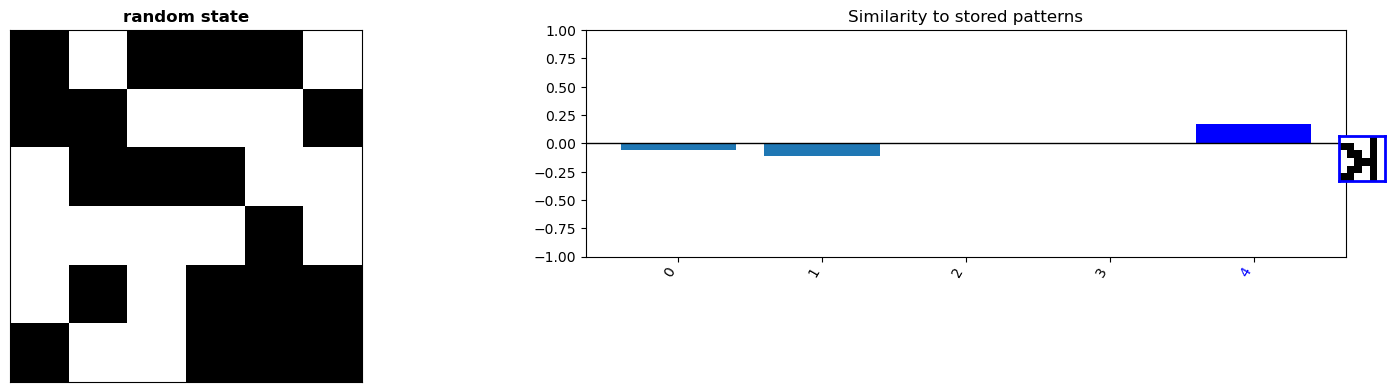

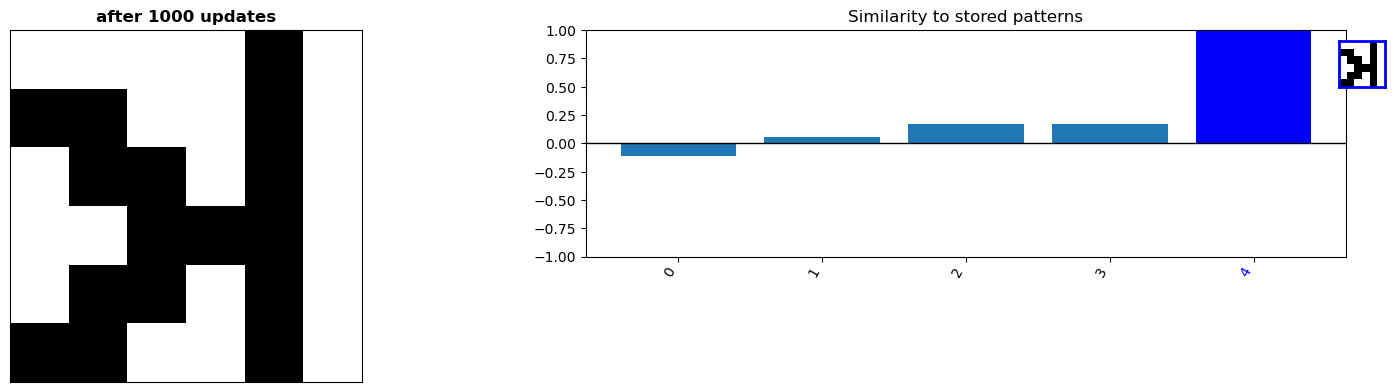

In [ ]:
HFN=HopfieldNetwork(patterns)
HFN.set_state(random=True)
HFN.visualise(title="random state")

for i in range(n_updates):
    HFN.update_state()

HFN.visualise(title=f"after {n_updates} updates")

## Image recognition

Starting from a stored pattern with some noise (20% of the neurons flipped), the network goes back to the original pattern. It starts to fail at about 35-40% of noise.

In [ ]:
def apply_noise(pattern, percentage=None):
    #flips the given percentage of randomly chosen neurons (default 20%), in place
    percentage= 20 if percentage is None else percentage

    pattern_size=pattern.shape[0]*pattern.shape[1]

    n_flips=round(pattern_size/100*percentage)
    
    already_flipped_cells=[]
    
    for i in range(n_flips):
        rand_row=np.random.randint(0,pattern.shape[0], size=1)
        rand_col= np.random.randint(0,pattern.shape[1], size=1)
        while (rand_row, rand_col) in already_flipped_cells: #avoid flipping twice the same neuron
            rand_row=np.random.randint(0,pattern.shape[0],size=1)
            rand_col=np.random.randint(0,pattern.shape[1],size=1)
    
        pattern[rand_row,rand_col]*=-1
        already_flipped_cells.append((rand_row,rand_col))

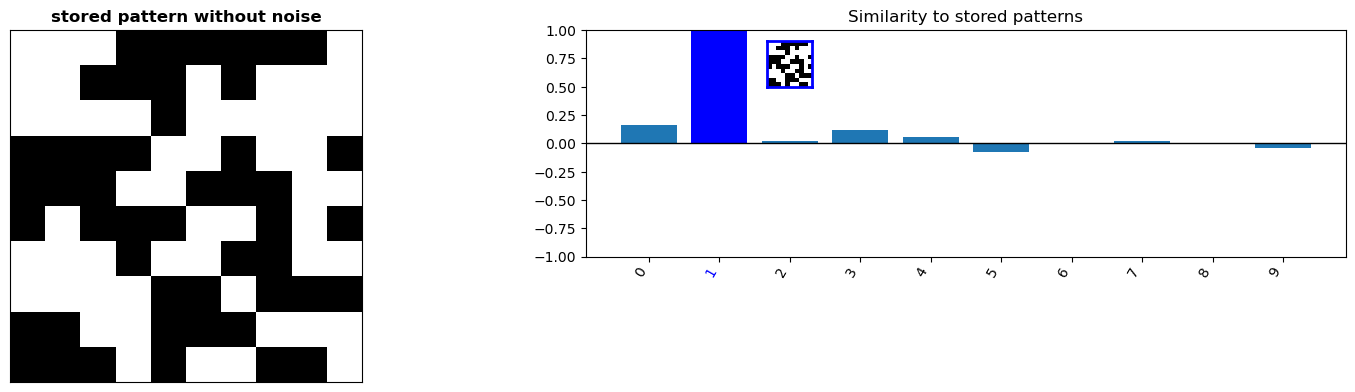

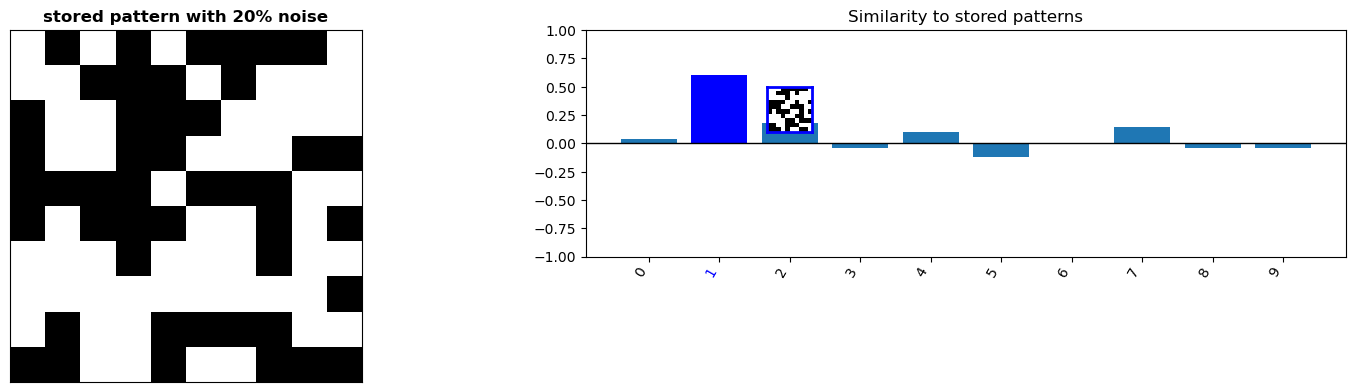

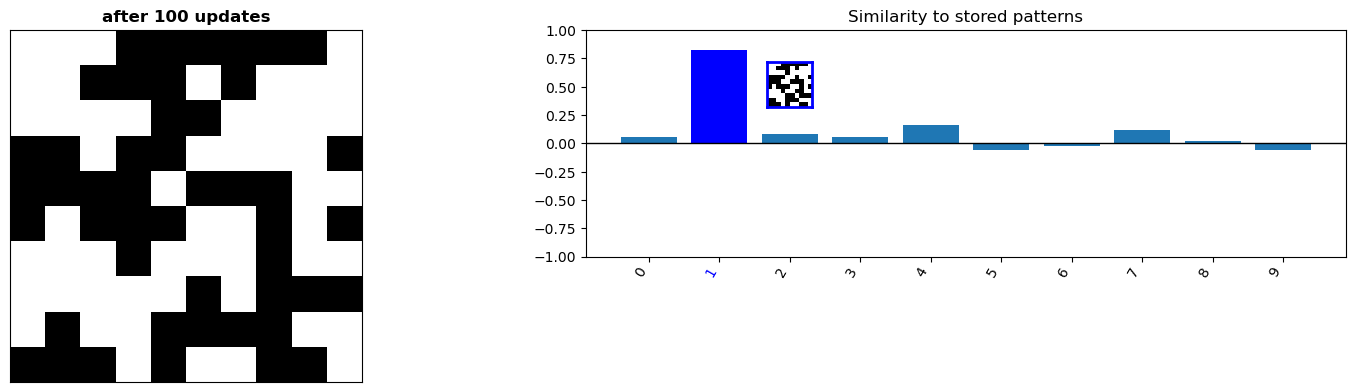

In [ ]:
pattern_size = 10
n_updates=100
N_patterns=10
memorized_patterns={i: np.random.choice([-1,1], (pattern_size,pattern_size)) for i in range (N_patterns)}
pattern_to_start = memorized_patterns[np.random.randint(0,N_patterns)]

#add some noise to the starting pattern
noisy_state=pattern_to_start.copy()
apply_noise(noisy_state)

HFN=HopfieldNetwork(memorized_patterns)
HFN.set_state(pattern_to_start.flatten())
HFN.visualise(title="stored pattern without noise")
HFN.set_state(noisy_state.flatten())
fig, ax=HFN.visualise(title="stored pattern with 20% noise")

for i in range(n_updates):
    HFN.update_state()
    
fig, ax=HFN.visualise(title=f"after {n_updates} updates")
plt.show()
#the network starts to fail at about 35-40% noise

The network can also recognise a pattern when only a part of it is given (here 75% of the pattern is masked).

In [ ]:
def apply_mask(pattern, mask_amount=None):
    """Masks 75% of the pattern, by setting to zero all the elements of the pattern except the top-left corner"""
    
    mask = np.zeros((pattern.shape[0], pattern.shape[1]))

    
    mask_amount=75 if mask_amount is None else mask_amount
    for row in range (pattern.shape[0]):
        for col in range(pattern.shape[1]):
            if row>(pattern.shape[0]*mask_amount/100) and col>np.floor(pattern.shape[1]*(1-mask_amount/100)):
                mask[row,col]=0
            elif row<=pattern.shape[0]*(1-mask_amount/100) and col<=np.floor(pattern.shape[1]*(1-mask_amount/100)):
                mask[row,col]=1
    
    return pattern * mask
#test
masked=apply_mask(pattern_to_start)
print(masked)

[[ 1.  1.  1. -0. -0. -0. -0. -0. -0.  0.]
 [ 1.  1. -1. -0. -0.  0. -0.  0.  0.  0.]
 [ 1.  1.  1.  0. -0.  0.  0.  0.  0.  0.]
 [-0. -0. -0. -0.  0.  0. -0.  0.  0. -0.]
 [-0. -0. -0.  0.  0. -0. -0. -0.  0.  0.]
 [-0.  0. -0. -0. -0.  0.  0. -0.  0. -0.]
 [ 0.  0.  0. -0.  0.  0. -0. -0.  0.  0.]
 [ 0.  0.  0.  0. -0. -0.  0. -0. -0. -0.]
 [-0. -0.  0.  0. -0. -0. -0.  0.  0.  0.]
 [-0. -0. -0.  0. -0.  0.  0. -0. -0.  0.]]


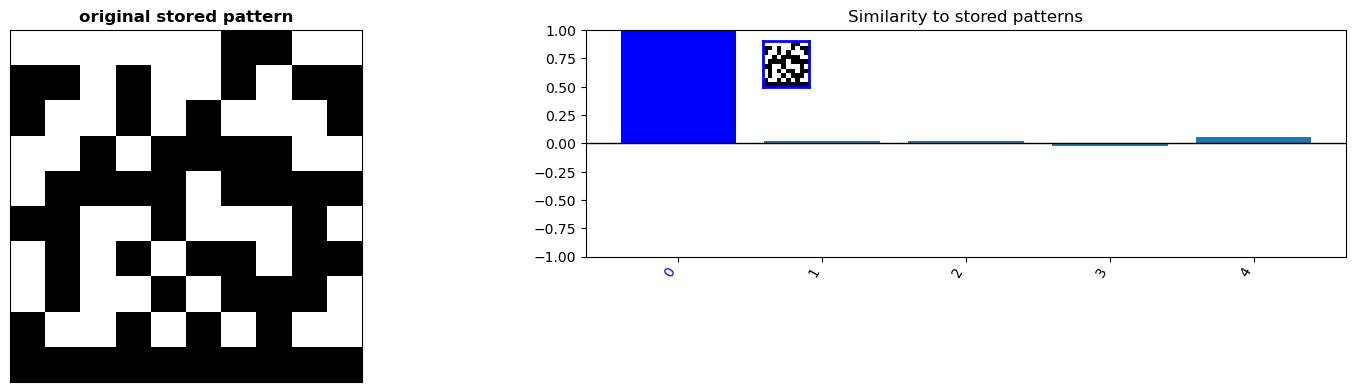

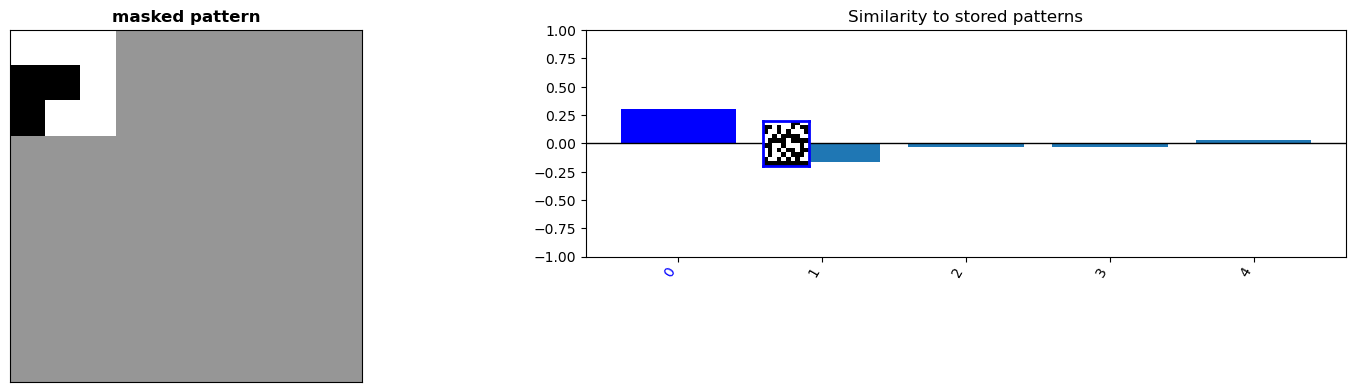

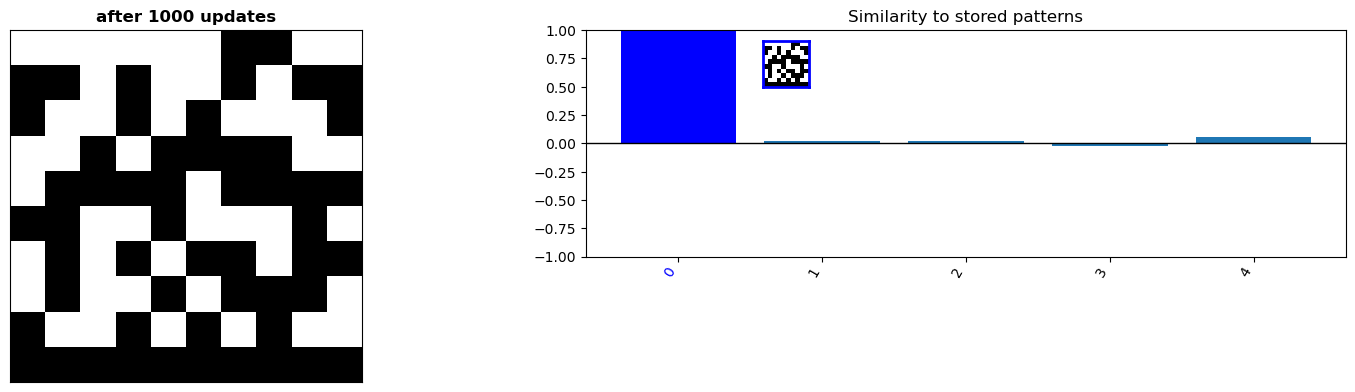

In [ ]:
pattern_size = 10
n_updates=1000
N_patterns=5 #with 10 patterns the network struggles: for 100 neurons the capacity is about 15
memorized_patterns={i: np.random.choice([-1,1], (pattern_size,pattern_size)) for i in range (N_patterns)}
pattern_to_start = memorized_patterns[np.random.randint(0,N_patterns)]
partially_masked_pattern = apply_mask(pattern_to_start)

HFN=HopfieldNetwork(memorized_patterns)
HFN.set_state(pattern_to_start.flatten())
HFN.visualise(title="original stored pattern")
HFN.set_state(partially_masked_pattern.flatten())
HFN.visualise(title="masked pattern")
for i in range(n_updates):
    HFN.update_state()
HFN.visualise(title=f"after {n_updates} updates")
plt.show()

## Other fixed points

Since the energy is quadratic in $\vec{s}$, also the negatives of the stored patterns $-x_i^{(\mu)}$ are minima, and so fixed points of the dynamics:

(<Figure size 1600x400 with 2 Axes>,
 array([<Axes: title={'center': 'after 1000 updates'}>,
        <Axes: title={'center': 'Similarity to stored patterns'}>],
       dtype=object))

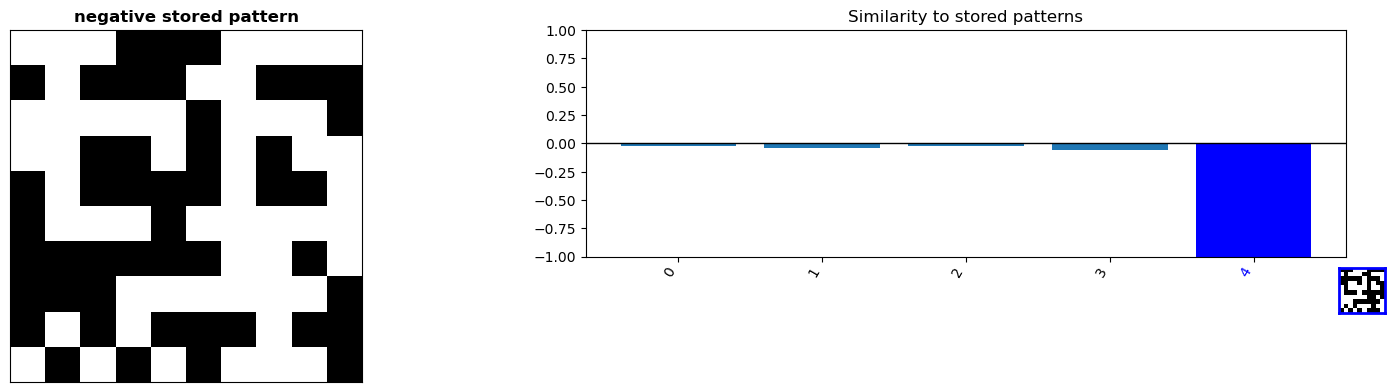

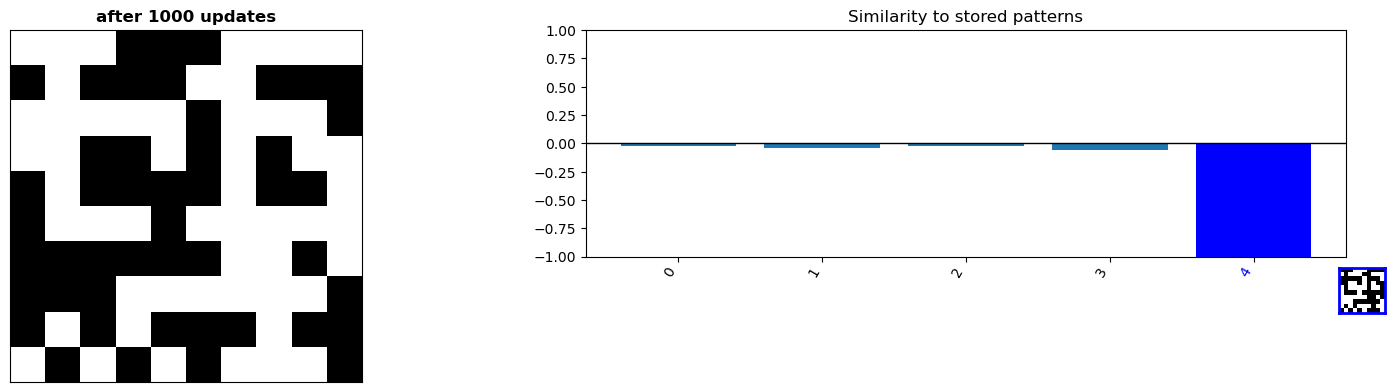

In [ ]:
memorized_patterns={i: np.random.choice([-1,1], (pattern_size,pattern_size)) for i in range (N_patterns)}

pattern = memorized_patterns[np.random.randint(0,N_patterns)]

negative_pattern = -1*pattern

HFN=HopfieldNetwork(memorized_patterns)

HFN.set_state(negative_pattern.flatten())


HFN.visualise(title="negative stored pattern")
for i in range(n_updates):
    HFN.update_state()
HFN.visualise(title=f"after {n_updates} updates") #the negative pattern is also a fixed point

Mixed states such as

$$ s_i(0) = \textrm{sgn} \big( \pm x_i^{(1)} \pm x_i^{(2)} \pm x_i^{(3)} \big)$$

are spurious fixed points as well:

(<Figure size 1600x400 with 2 Axes>,
 array([<Axes: title={'center': 'after 100000 updates'}>,
        <Axes: title={'center': 'Similarity to stored patterns'}>],
       dtype=object))

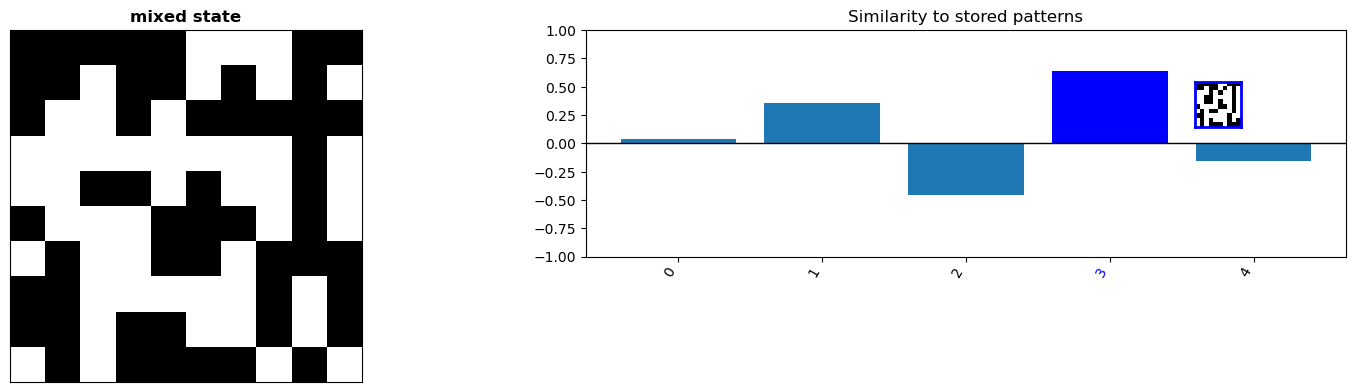

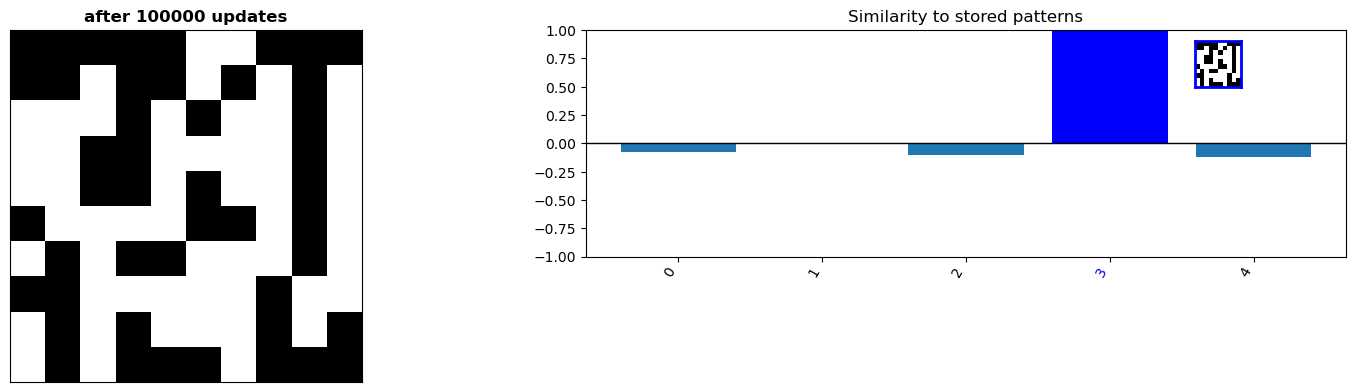

In [ ]:
##### define a mixed state
n_updates=100000
random_patterns={i: np.random.choice([-1,1], (pattern_size,pattern_size)) for i in range (N_patterns)}
mixed_state = np.sign(random_patterns[1].flatten() - random_patterns[2].flatten() + random_patterns[3].flatten())
#reinitialise the state of the network, evolve it for several steps and then visualise 
HFN=HopfieldNetwork(random_patterns)
HFN.set_state(mixed_state)
HFN.visualise(title="mixed state")
for i in range(n_updates):
    HFN.update_state()
HFN.visualise(title=f"after {n_updates} updates")
#the mixed state is a spurious fixed point of the dynamics

## Storage capacity

The number of patterns a classical Hopfield network can store is about

$$
C\approx\frac{N}{2\log_2 N}
$$

Storing 20 patterns of $4\times4$ pixels, well above the capacity, most of the stored patterns are not fixed points anymore.

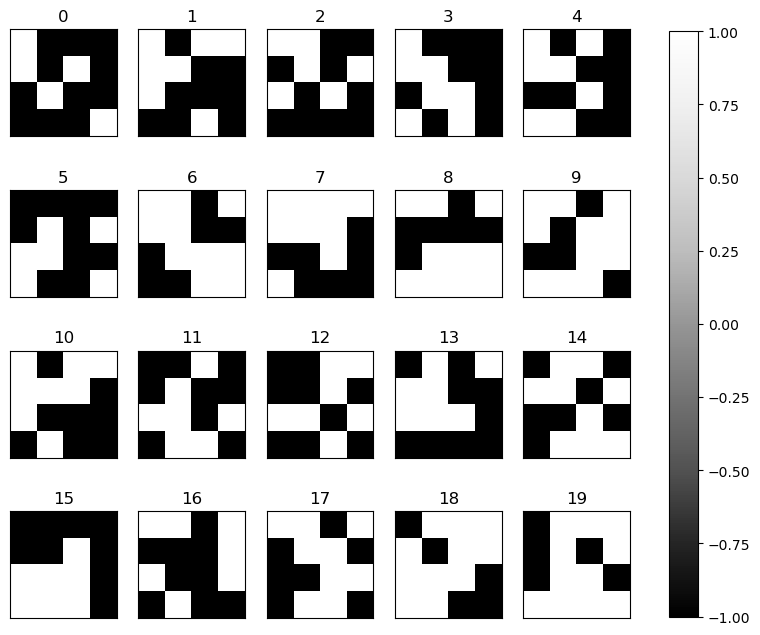

In [ ]:
#Create 20 random patterns of size 4x4
N_patterns = 20
pattern_size = 4
random_patterns_20 = {i: np.random.choice([-1,1], (pattern_size, pattern_size)) for i in range (N_patterns)}

fig, ax = plot_patterns(random_patterns_20)

HFN = HopfieldNetwork(random_patterns_20)

pattern number 1 is ''unstable'' 
pattern number 2 is ''unstable'' 
pattern number 3 is ''unstable'' 
pattern number 4 is ''stable'' as it is a fixed point of the network's dynamics
pattern number 5 is ''unstable'' 
pattern number 6 is ''unstable'' 
pattern number 7 is ''unstable'' 
pattern number 8 is ''stable'' as it is a fixed point of the network's dynamics
pattern number 9 is ''unstable'' 
pattern number 10 is ''unstable'' 
pattern number 11 is ''unstable'' 
pattern number 12 is ''unstable'' 
pattern number 13 is ''stable'' as it is a fixed point of the network's dynamics
pattern number 14 is ''unstable'' 
pattern number 15 is ''unstable'' 
pattern number 16 is ''unstable'' 
pattern number 17 is ''stable'' as it is a fixed point of the network's dynamics
pattern number 18 is ''unstable'' 
pattern number 19 is ''unstable'' 
pattern number 20 is ''unstable'' 
in this case, stable patterns are 20.0% of the total stored ones 
 Here follows a visualization of the evolution of a stable 

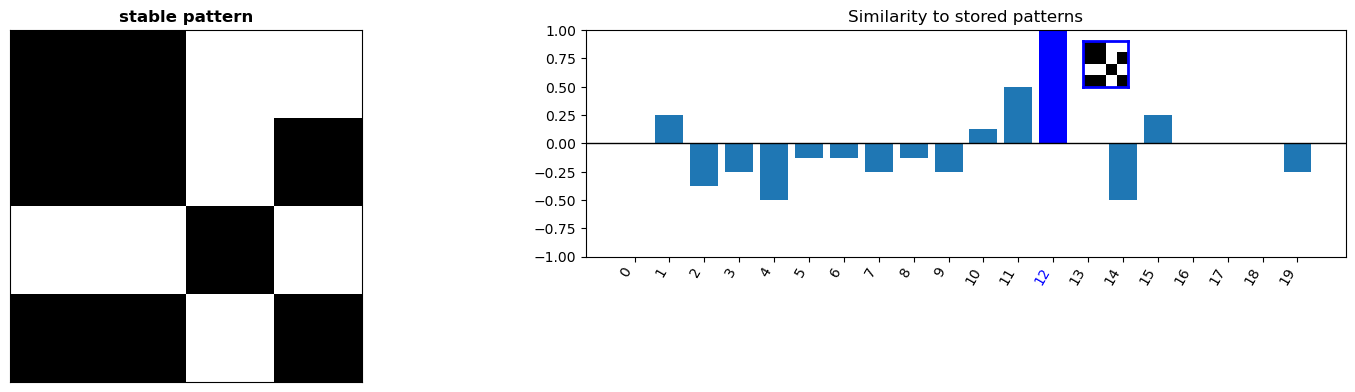

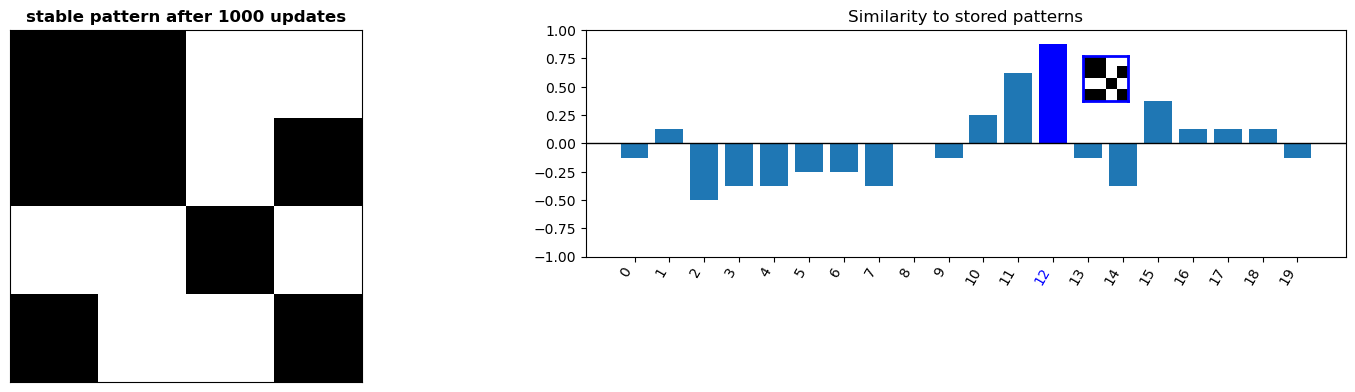

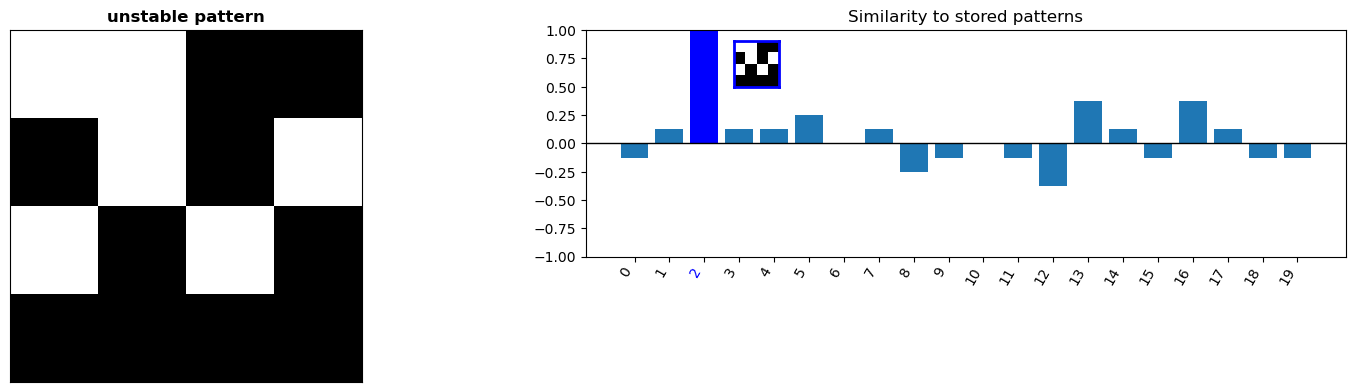

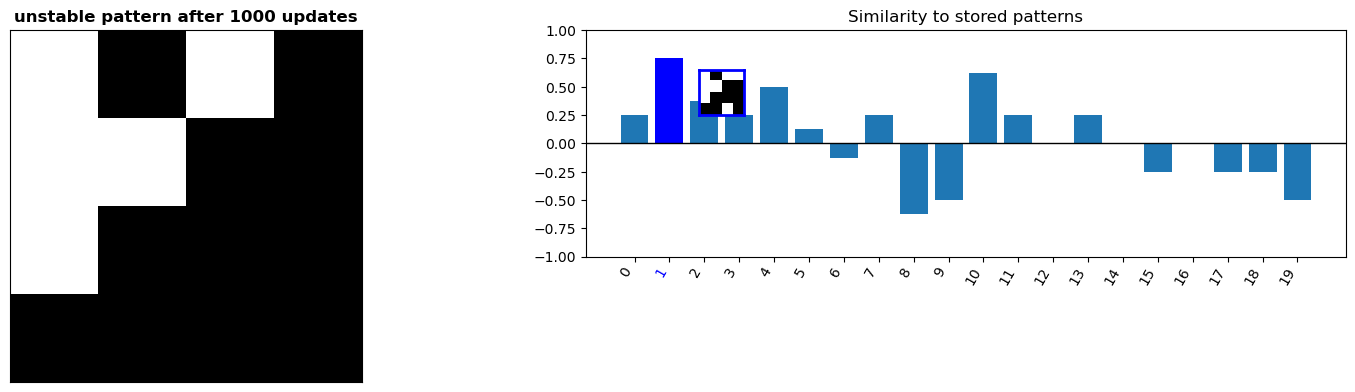

In [ ]:
# Try to start from all the stored patterns and find the stable or unstable ones.
n_updates=1000
stable_index=[]
unstable_index=[i for i in range (N_patterns)]
for i in range (N_patterns):
    HFN.set_state(random_patterns_20[i].flatten())
   
    for j in range (n_updates):
        HFN.update_state()
        
    if np.isclose(HFN.similarities[i],1, atol=0.2):
        print(f"pattern number {i+1} is ''stable'' as it is a fixed point of the network's dynamics")
        stable_index.append(i)
        unstable_index.remove(i)
    else:
        print(f"pattern number {i+1} is ''unstable'' ")
if not stable_index:
    print("no stable patterns found, please restart the network with new random patterns")
else:
    print(f"in this case, stable patterns are {len(stable_index)/N_patterns*100}% of the total stored ones \n Here follows a visualization of the evolution of a stable pattern and an unstable one:")
    
    HFN.set_state(random_patterns_20[np.random.choice(stable_index)].flatten())

    HFN.visualise(title="stable pattern")
    for i in range (n_updates):
        HFN.update_state()
  
    HFN.visualise(title=f"stable pattern after {n_updates} updates")
    
    HFN.set_state(random_patterns_20[np.random.choice(unstable_index)].flatten())

    HFN.visualise(title="unstable pattern")
    for i in range (n_updates):
        HFN.update_state()

    HFN.visualise(title=f"unstable pattern after {n_updates} updates")
    plt.show()

## Complex patterns

With larger grayscale images the classical network does not work well: the patterns are not binary and they are strongly correlated with each other (for images with a subject in the middle of a uniform background), so the network ends up in mixtures of them.

In [ ]:
import cv2
import os

# grayscale PNG images of the same size, rescaled to [-1, 1] (see the README)
directory = "images"
patterns = {}

for filename in sorted(os.listdir(directory)):
    if filename.endswith(".png"):
        img = cv2.imread(os.path.join(directory, filename), cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise ValueError(f"Could not load {filename}")
        patterns[filename[:-4]] = (img / 255) * 2 - 1

In [ ]:
# Initialise a new Hopfield network with the new patterns
HFN = HopfieldNetwork(patterns)

In [ ]:
name = list(patterns.keys())[0]
n_updates=100
HFN.set_state(patterns[name].flatten()) #reinitialise the state of the network
HFN.visualise(title=f"Initial state {name}")

for i in range(n_updates):
    HFN.update_state(asynchronous=True)

HFN.visualise(title=f"State after {n_updates} updates")

In [ ]:
name = list(patterns.keys())[1]
n_updates=1000
masked=apply_mask(patterns[name], mask_amount=50)

HFN.set_state(masked.flatten()) #reinitialise the state of the network

HFN.visualise(title=f"Initial state {name}")
for i in range(n_updates):
    HFN.update_state(asynchronous=True)

HFN.visualise(title=f"State after {n_updates} updates")

## Modern Hopfield networks

The performance improves a lot by changing the energy function and the update rule:

| | **Classic** | **Modern** |
| ----------- | ----------- | ----------- |
| **Update rule** | $ \vec{s} \leftarrow \textrm{sign}\big(\underbrace{\vec{x}\vec{x}^{\mathsf{T}}}_{\mathsf{J}}\vec{s}\big)$ | $\vec{s} \leftarrow \vec{x} \textrm{softmax}(\beta \vec{x}^{\mathsf{T}}\vec{s})$ |
| **Energy function** | $ E(\vec{s}) = \vec{s}^{\mathsf{T}}\underbrace{\vec{x}\vec{x}^{\mathsf{T}}}_{\mathsf{J}}\vec{s}$ | $E(\vec{s}) = -\textrm{lse}\big(\vec{x}^{\mathsf{T}}\vec{s}\big) + \frac{1}{2} \vec{s}^{\mathsf{T}}\vec{s}$ |

where $\text{softmax}(\mathbf{x})_i = \frac{e^{x_i}}{\sum_{j}e^{x_j}}$ and $\text{lse}(\mathbf{x})=\log\sum_{i}e^{x_i}$. The modern network inherits everything from the classical one except the update rule and the energy.

In [ ]:
def softmax(x):
    return np.exp(x)/np.sum(np.exp(x))

def log_sum_exp(x, beta=1):
    """Numerically stable log-sum-exp: the maximum is subtracted before the
    exponential (to avoid overflow) and added back outside the log."""
    xmax=np.max(x)
    return np.log(np.sum(np.exp(beta * (x-xmax)))) +xmax/beta

In [ ]:
class ModernHopfieldNetwork(HopfieldNetwork):
    def __init__(self,patterns,beta=0.01):
        self.beta = beta
        super().__init__(patterns)
    
    def update_state(self):
        """Modern update rule, with a softmax over the similarities to the stored patterns"""
        self.state = self.flat_patterns.T @ softmax(self.beta * np.dot(self.flat_patterns, self.state))

        self.similarities = self.get_similarities()
        self.energy = self.get_energy()
        self.save_history()
 
    def get_energy(self,state=None):
        state = self.state if state is None else state
        return -log_sum_exp(np.dot(self.flat_patterns,state))+0.5*np.dot(state.T,state)

Starting from a random state, the modern network converges to one of the stored images:

In [ ]:
MHFN = ModernHopfieldNetwork(patterns)
MHFN.set_state(random=True)
MHFN.visualise()
for i in range (n_updates):
    MHFN.update_state()
MHFN.visualise(title=f"State after {n_updates} updates")
MHFN.plot_energy(n_steps=100)
plt.show()

It also recognises noisy (30% of flipped pixels) and partially masked images:

In [ ]:
### START WITH THE NOISY PATTERN...

pattern_to_start = patterns[np.random.choice(list(patterns.keys()))]

X = 30 # percentage of bits to flip 

noisy_pattern = pattern_to_start.copy()
apply_noise(noisy_pattern, percentage=X)

#reinitialise the state of the network, evolve it for several steps and then visualise 

MHFN=ModernHopfieldNetwork(patterns)
MHFN.set_state(noisy_pattern.flatten())
MHFN.visualise(title=f"{X}% noise state")
for i in range(n_updates):
    MHFN.update_state()

MHFN.visualise(title=f"State after {n_updates} updates")
plt.show()

In [ ]:
### ... NOW DO THE SAME WITH THE MASKED PATTERN

pattern_to_start = patterns[np.random.choice(list(patterns.keys()))]

masked = apply_mask(pattern_to_start,mask_amount=40)

#reinitialise the state of the network, evolve it for several steps and then visualise 

MHFN=ModernHopfieldNetwork(patterns)

MHFN.set_state(masked.flatten())

MHFN.visualise(title="masked state")
for i in range(n_updates):
    MHFN.update_state()
MHFN.visualise(title=f"State after {i+1} updates")
plt.show()

## Temperature

$\beta$ plays the role of an inverse temperature. At high temperature ($\beta = 0.001$) the network converges to metastable states:

In [ ]:
MHFN=ModernHopfieldNetwork(patterns, beta=0.001)

MHFN.set_state(random= True)


MHFN.visualise()
for i in range(n_updates):
    MHFN.update_state()

MHFN.visualise()
plt.show()

The network with high temperature converges into a metastable state, which is a local minimum of the energy function of the system. This occurs because, for lower beta, the "thermal noise" becomes more strong and the network fails to recognize one pattern among all the stored ones. Mathematically, the issue lies in the update rule: the softmax function turns the data in to a normalized probability distribution. Therefore, if the input values are very small (which happens for lower beta) the softmax tends to return an uniform distribution over the states. This means that the network will find it more difficult to converge to a precise state and will instead become trapped into a mixture of the stored patterns.